# Pipeline Huan Luyen YOLO26s SOTA Cho Phat Hien PPE tren Kaggle (16GB VRAM)

**Muc tieu:** Train 1 lan duy nhat voi cau hinh toi uu cho GPU 16GB (T4/P100) tren Kaggle.

**Cac cai tien so voi ban Local:**
- `batch = -1` — Ultralytics tu dong chon batch phu hop VRAM, tranh OOM tren T4/P100
- `epochs = 200` voi `patience = 50` — hoi tu sau hon
- `workers = 2` — can bang toc do doc du lieu va do on dinh tren Kaggle
- `close_mosaic = 20` — tat mosaic o giai doan cuoi de tinh chinh hop ly hon
- `copy_paste = 0.1` va `erasing = 0.2` — augmentation vua phai cho PPE/small objects
- `amp = True` — giam VRAM va tang toc train tren GPU
- Tu dong xu ly `data.yaml` path cho Kaggle va tu chon split danh gia

## 1. Cai Dat Thu Vien & Kiem Tra GPU


In [ ]:

import os
import sys
import yaml
import shutil
from pathlib import Path
import torch
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO
import ultralytics

# Kiem tra GPU va phien ban Ultralytics
assert tuple(map(int, ultralytics.__version__.split('.')[:2])) >= (8, 4), (
    f"Can Ultralytics >= 8.4 de dung YOLO26, dang co {ultralytics.__version__}"
)
device = '0' if torch.cuda.is_available() else 'cpu'
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_mb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 2)
    print(f"GPU: {gpu_name} ({vram_mb:.0f} MB VRAM)")
    torch.cuda.empty_cache()
else:
    print("Khong tim thay GPU, su dung CPU.")
print(f"Ultralytics: {ultralytics.__version__}")

# Uu tien checkpoint da upload; neu khong co, Ultralytics se tai yolo26s.pt.
checkpoint_candidates = [Path.cwd() / 'yolo26s.pt']
if os.path.exists('/kaggle/input'):
    checkpoint_candidates.extend(sorted(Path('/kaggle/input').rglob('yolo26s.pt')))
LOCAL_CHECKPOINT = next((path for path in checkpoint_candidates if path.exists()), None)
MODEL_SOURCE = str(LOCAL_CHECKPOINT) if LOCAL_CHECKPOINT else 'yolo26s.pt'
print(f"Checkpoint: {MODEL_SOURCE}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.7/88.7 kB 8.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4 (14912 MB VRAM)
Ultralytics: 8.4.159
Checkpoint: yolo26s.pt


## 2. Thiet Lap Dataset & Xu Ly data.yaml cho Kaggle


In [2]:
# Tu dong detect moi truong va dataset 5 class
IS_KAGGLE = os.path.exists('/kaggle/input')
EXPECTED_CLASSES = ["person", "helmet", "vest", "gloves", "boots"]


def find_five_class_yaml(search_root):
    candidates = sorted(Path(search_root).rglob('data.yaml'))
    for candidate in candidates:
        try:
            with open(candidate, 'r', encoding='utf-8') as file:
                metadata = yaml.safe_load(file) or {}
            names = metadata.get('names', [])
            if isinstance(names, dict):
                names = [names[index] for index in sorted(names)]
            normalized_names = [str(name).strip().lower() for name in names]
            if normalized_names == EXPECTED_CLASSES:
                return candidate
        except (OSError, TypeError, ValueError):
            continue
    return None


def has_images_and_labels(dataset_dir, split_name):
    image_dir = dataset_dir / 'images' / split_name
    label_dir = dataset_dir / 'labels' / split_name
    image_count = sum(
        len(list(image_dir.glob(pattern))) for pattern in ('*.jpg', '*.jpeg', '*.png')
    ) if image_dir.exists() else 0
    label_count = len(list(label_dir.glob('*.txt'))) if label_dir.exists() else 0
    return image_count > 0 and label_count > 0


if IS_KAGGLE:
    print("Moi truong: KAGGLE")
    source_yaml = find_five_class_yaml('/kaggle/input')
    if source_yaml is None:
        raise FileNotFoundError(
            "Khong tim thay data.yaml 5 class trong /kaggle/input. "
            "Dataset can co names: person, helmet, vest, gloves, boots."
        )
    INPUT_DIR = source_yaml.parent
    DATASET_DIR = Path('/kaggle/working/dataset')
    if DATASET_DIR.exists():
        print(f"Xoa dataset cu de tranh dung nham du lieu: {DATASET_DIR}")
        shutil.rmtree(DATASET_DIR)
    print(f"Dang copy dataset 5 class tu {INPUT_DIR}...")
    shutil.copytree(str(INPUT_DIR), str(DATASET_DIR))
    print(f"Da copy xong: {DATASET_DIR}")

    DATA_YAML = DATASET_DIR / "data.yaml"
    with open(DATA_YAML, 'r', encoding='utf-8') as file:
        yaml_data = yaml.safe_load(file) or {}
    yaml_data['path'] = str(DATASET_DIR)
    yaml_data['train'] = 'images/train'
    yaml_data['val'] = 'images/val'
    if has_images_and_labels(DATASET_DIR, 'test'):
        yaml_data['test'] = 'images/test'
    else:
        yaml_data.pop('test', None)
    yaml_data['names'] = EXPECTED_CLASSES
    with open(DATA_YAML, 'w', encoding='utf-8') as file:
        yaml.safe_dump(yaml_data, file, sort_keys=False, default_flow_style=False)
else:
    print("Moi truong: LOCAL")
    DATASET_DIR = Path.cwd() / 'dataset'
    DATA_YAML = DATASET_DIR / 'data.yaml'

assert DATA_YAML.exists(), (
    f"Khong tim thay dataset 5 class tai {DATA_YAML}. "
    "Dat dataset vao train/dataset hoac them dataset 5 class vao Kaggle Input."
)
assert (DATASET_DIR / 'images' / 'train').exists(), "Thieu thu muc images/train"
assert (DATASET_DIR / 'images' / 'val').exists(), "Thieu thu muc images/val"

EVAL_SPLIT = 'test' if has_images_and_labels(DATASET_DIR, 'test') else 'val'
EVAL_BATCH = 8 if torch.cuda.is_available() else 1
CLASS_NAMES = EXPECTED_CLASSES
CLASS_COLORS = {
    0: (52, 152, 219),
    1: (241, 196, 15),
    2: (230, 126, 34),
    3: (46, 204, 113),
    4: (155, 89, 182),
}

with open(DATA_YAML, 'r', encoding='utf-8') as file:
    dataset_meta = yaml.safe_load(file) or {}
dataset_names = dataset_meta.get('names', [])
if isinstance(dataset_names, dict):
    dataset_names = [dataset_names[index] for index in sorted(dataset_names)]
dataset_names = [str(name).strip().lower() for name in dataset_names]
assert dataset_names == CLASS_NAMES, (
    f"Dataset phai dung dung 5 class theo thu tu {CLASS_NAMES}, found={dataset_names}"
)

PROJECT_ROOT = Path('/kaggle/working') if IS_KAGGLE else Path.cwd()
print(f"Dataset: {DATASET_DIR}")
print(f"data.yaml: {DATA_YAML}")
print(f"5 lop: {CLASS_NAMES}")
print(f"Split danh gia: {EVAL_SPLIT}")

for split in ['train', 'val', 'test']:
    img_dir = DATASET_DIR / 'images' / split
    if img_dir.exists():
        count = len(list(img_dir.glob('*.jpg')) + list(img_dir.glob('*.jpeg')) + list(img_dir.glob('*.png')))
        print(f"  {split}: {count} anh")

Moi truong: KAGGLE
Dang copy dataset 5 class tu /kaggle/input/datasets/xunbch1/5ppeclasses...
Da copy xong: /kaggle/working/dataset
Dataset: /kaggle/working/dataset
data.yaml: /kaggle/working/dataset/data.yaml
5 lop: ['person', 'helmet', 'vest', 'gloves', 'boots']
Split danh gia: test
  train: 1132 anh
  val: 143 anh
  test: 141 anh


## 3. Cau Hinh YOLO26 cho Kaggle

| Tham so | Gia tri | Ly do |
| :--- | :---: | :--- |
| `imgsz` | `800` | Do phan giai cao cho small objects (boots, gloves) |
| `epochs` | `200` | Hoi tu sau hon, early stopping se tu dung |
| `patience` | `50` | Du thoi gian vuot qua plateau |
| `batch` | `-1` | Tu dong chon batch theo VRAM, giam nguy co OOM |
| `box` | `7.5` | Loss box cua Ultralytics YOLO26 |
| `cls` | `0.5` | Gia tri mac dinh YOLO26, phu hop 5 lop |
| `dfl` | `1.5` | Loss phan phoi box cua YOLO26 |
| `cos_lr` | `True` | Cosine learning-rate schedule |
| `close_mosaic` | `20` | Tat mosaic o 20 epoch cuoi |
| `copy_paste` | `0.1` | Tang mau nhe cho small objects |
| `erasing` | `0.2` | Chong overfit nhung khong lam mat PPE qua nhieu |
| `mixup` | `0.05` | Muc nhe de tranh mo small objects |
| `amp` | `True` | Tiet kiem VRAM va tang toc tren T4/P100 |

In [3]:
CONFIG = {
    "model_name": MODEL_SOURCE,

    "train_params": {
        "data": str(DATA_YAML),
        "epochs": 200,
        "patience": 50,
        "imgsz": 800,
        "batch": -1,
        "device": device,
        "workers": 2 if IS_KAGGLE else 0,

        # Loss weights theo default YOLO26
        "box": 7.5,
        "cls": 0.5,
        "dfl": 1.5,

        # Optimization
        "cos_lr": True,
        "close_mosaic": 20,
        "optimizer": "auto",
        "amp": True,
        "seed": 42,
        "deterministic": False,
        "pretrained": True,
        "save_period": 25,

        # Augmentation
        "mosaic": 1.0,
        "copy_paste": 0.1,
        "mixup": 0.05,
        "scale": 0.5,
        "translate": 0.1,
        "degrees": 5.0,
        "fliplr": 0.5,
        "erasing": 0.2,

        # Output
        "project": str(PROJECT_ROOT / "runs" / "ppe"),
        "name": "yolo26s_5class_kaggle_sota",
        "exist_ok": True,
        "save": True,
        "plots": True,
        "verbose": True,
    },

    "dynamic_thresholds": {
        0: 0.35,
        1: 0.30,
        2: 0.30,
        3: 0.18,
        4: 0.16,
    },

    "run_training": True,
}

RUN_DIR = Path(CONFIG["train_params"]["project"]) / CONFIG["train_params"]["name"]

print("=== CAU HINH YOLO26 5 CLASS KAGGLE ===")
tp = CONFIG['train_params']
print(f"  Model    : {CONFIG['model_name']}")
print(f"  imgsz    : {tp['imgsz']}x{tp['imgsz']}")
print(f"  epochs   : {tp['epochs']} (patience={tp['patience']})")
print(f"  batch    : {tp['batch']} (auto theo VRAM)")
print(f"  workers  : {tp['workers']}")
print(f"  Loss     : box={tp['box']}, cls={tp['cls']}, dfl={tp['dfl']}")
print(f"  Augment  : copy_paste={tp['copy_paste']}, mixup={tp['mixup']}, erasing={tp['erasing']}")
print(f"  Output   : {RUN_DIR}")
print(f"  Thresholds: {CONFIG['dynamic_thresholds']}")

=== CAU HINH YOLO26 5 CLASS KAGGLE ===
  Model    : yolo26s.pt
  imgsz    : 800x800
  epochs   : 200 (patience=50)
  batch    : -1 (auto theo VRAM)
  workers  : 2
  Loss     : box=7.5, cls=0.5, dfl=1.5
  Augment  : copy_paste=0.1, mixup=0.05, erasing=0.2
  Output   : /kaggle/working/runs/ppe/yolo26s_5class_kaggle_sota
  Thresholds: {0: 0.35, 1: 0.3, 2: 0.3, 3: 0.18, 4: 0.16}


## 4. Huan Luyen


In [4]:
if CONFIG["run_training"]:
    print(f"Bat dau huan luyen {CONFIG['model_name']}...")
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    model = YOLO(CONFIG["model_name"])
    results = model.train(**CONFIG["train_params"])
    best_weights_path = Path(results.save_dir) / "weights" / "best.pt"
    print(f"Hoan thanh! Trong so luu tai: {best_weights_path}")
else:
    # Tim trong so YOLO26 san co
    candidates = [
        RUN_DIR / "weights" / "best.pt",
        PROJECT_ROOT / "runs" / "ppe" / "yolo26s_5class_baseline" / "weights" / "best.pt",
        PROJECT_ROOT / "runs" / "ppe" / "yolo26s_5class_sota" / "weights" / "best.pt",
    ]
    best_weights_path = None
    for candidate in candidates:
        if candidate.exists():
            best_weights_path = candidate
            break
    if best_weights_path:
        print(f"Dang su dung trong so: {best_weights_path}")
    else:
        print("Khong tim thay trong so. Hay bat run_training = True.")

Bat dau huan luyen yolo26s.pt...
Ultralytics 8.4.159 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/dataset/data.yaml, degrees=5.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.2, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s_

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/200      4.18G      1.759      1.938    0.02023         51        800: 100% ━━━━━━━━━━━━ 162/162 5.9it/s 27.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 6.5it/s 1.7s
                   all        143        898      0.759      0.633      0.711       0.34

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      3/200      4.18G      1.783      1.728    0.02098         61        800: 100% ━━━━━━━━━━━━ 162/162 5.7it/s 28.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 6.4it/s 1.7s
                   all        143        898      0.723      0.702      0.732      0.336

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      4/200      4.18G      1.762      1.668    0.02103         90        800: 100% ━━━━━━━━━━━━ 162/162 5.4it/s 29.8s
                 Class     Images  Instances      Box

## 5. Truc Quan Hoa Tien Trinh Huan Luyen


Da nap 154 epochs tu: results.csv


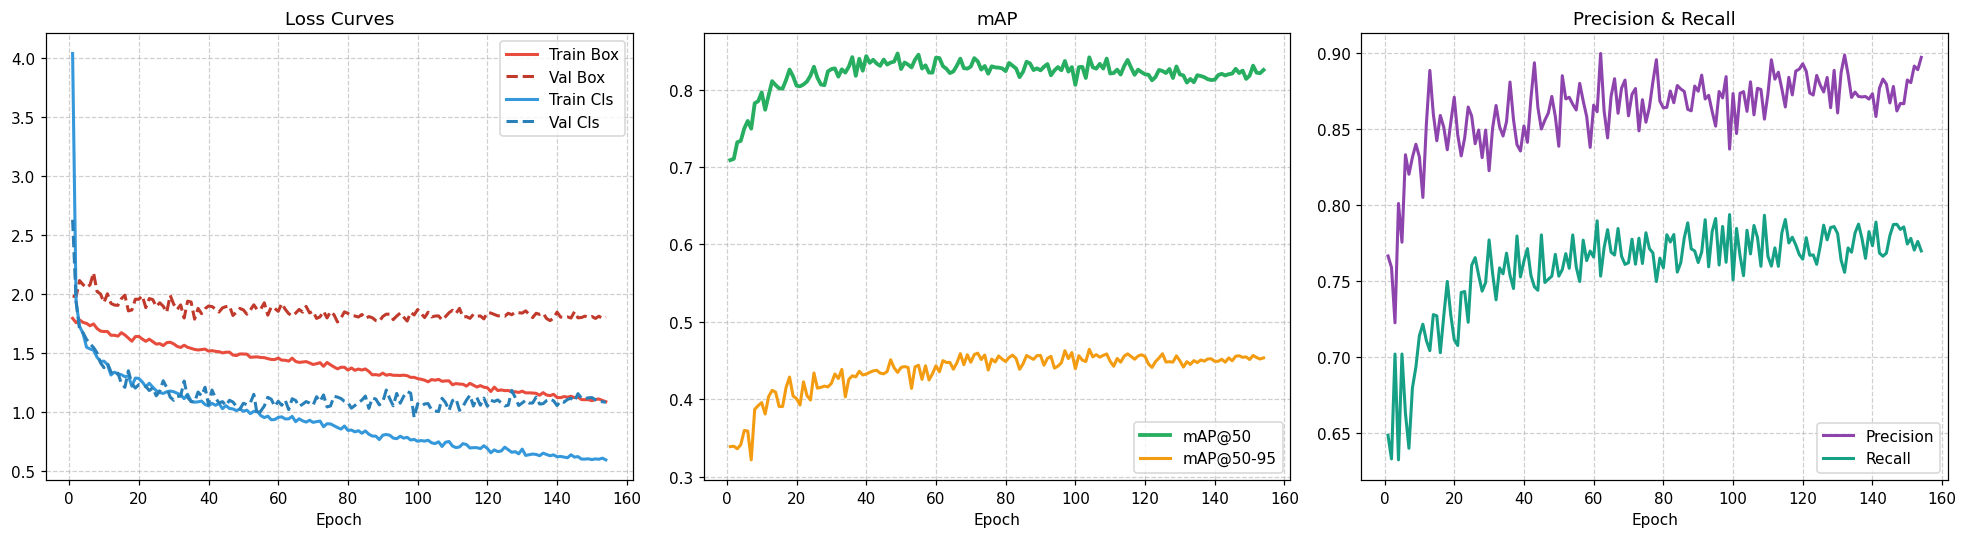

In [5]:
results_csv = RUN_DIR / "results.csv"

if results_csv.exists():
    df_res = pd.read_csv(results_csv)
    df_res.columns = [c.strip() for c in df_res.columns]
    print(f"Da nap {len(df_res)} epochs tu: {results_csv.name}")

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=110)

    axes[0].plot(df_res['epoch'], df_res['train/box_loss'], label='Train Box', color='#e74c3c', lw=2)
    if 'val/box_loss' in df_res.columns:
        axes[0].plot(df_res['epoch'], df_res['val/box_loss'], label='Val Box', color='#c0392b', ls='--', lw=2)
    axes[0].plot(df_res['epoch'], df_res['train/cls_loss'], label='Train Cls', color='#3498db', lw=2)
    if 'val/cls_loss' in df_res.columns:
        axes[0].plot(df_res['epoch'], df_res['val/cls_loss'], label='Val Cls', color='#2980b9', ls='--', lw=2)
    axes[0].set_title('Loss Curves'); axes[0].set_xlabel('Epoch')
    axes[0].grid(True, ls='--', alpha=0.6); axes[0].legend()

    axes[1].plot(df_res['epoch'], df_res['metrics/mAP50(B)'], label='mAP@50', color='#27ae60', lw=2.5)
    axes[1].plot(df_res['epoch'], df_res['metrics/mAP50-95(B)'], label='mAP@50-95', color='#f39c12', lw=2)
    axes[1].set_title('mAP'); axes[1].set_xlabel('Epoch')
    axes[1].grid(True, ls='--', alpha=0.6); axes[1].legend()

    axes[2].plot(df_res['epoch'], df_res['metrics/precision(B)'], label='Precision', color='#8e44ad', lw=2)
    axes[2].plot(df_res['epoch'], df_res['metrics/recall(B)'], label='Recall', color='#16a085', lw=2)
    axes[2].set_title('Precision & Recall'); axes[2].set_xlabel('Epoch')
    axes[2].grid(True, ls='--', alpha=0.6); axes[2].legend()

    plt.tight_layout()
    plt.show()
else:
    print("Chua co results.csv.")

## 6. Confusion Matrix & PR Curve


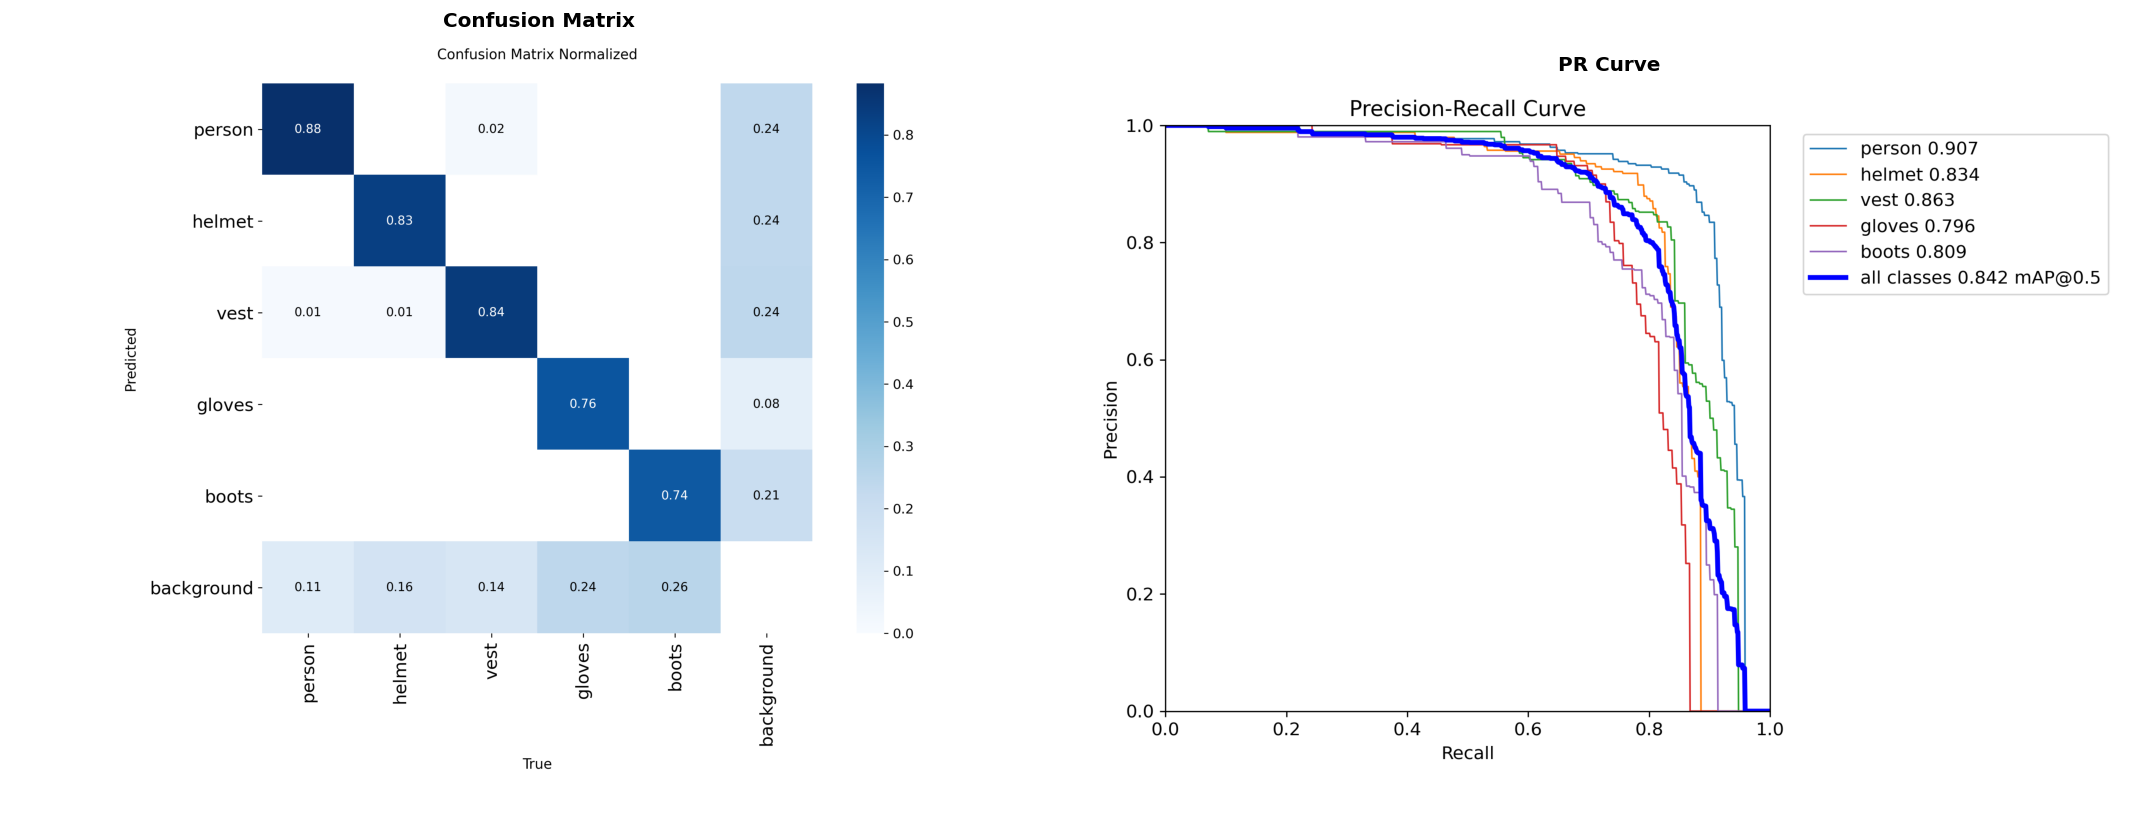

In [6]:
plots_dir = RUN_DIR

if plots_dir.exists():
    cm_path = plots_dir / "confusion_matrix_normalized.png"
    pr_path = plots_dir / "BoxPR_curve.png"

    fig, axes = plt.subplots(1, 2, figsize=(18, 8), dpi=120)

    if cm_path.exists():
        img_cm = cv2.imread(str(cm_path))
        axes[0].imshow(cv2.cvtColor(img_cm, cv2.COLOR_BGR2RGB))
        axes[0].set_title('Confusion Matrix', fontsize=12, fontweight='bold')
        axes[0].axis('off')
    else:
        axes[0].text(0.5, 0.5, 'Chua co confusion matrix', ha='center', va='center')
        axes[0].axis('off')

    if pr_path.exists():
        img_pr = cv2.imread(str(pr_path))
        axes[1].imshow(cv2.cvtColor(img_pr, cv2.COLOR_BGR2RGB))
        axes[1].set_title('PR Curve', fontsize=12, fontweight='bold')
        axes[1].axis('off')
    else:
        axes[1].text(0.5, 0.5, 'Chua co PR curve', ha='center', va='center')
        axes[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Chua co thu muc ket qua.")

## 7. Danh Gia Tren Tap Test & Nguong Dong Per-Class


In [7]:
if best_weights_path and best_weights_path.exists():
    eval_model = YOLO(str(best_weights_path))
    test_metrics = eval_model.val(
        data=str(DATA_YAML), split=EVAL_SPLIT, imgsz=CONFIG['train_params']['imgsz'],
        batch=EVAL_BATCH, conf=0.25, device=device, verbose=False
    )
    print(f"\nKET QUA TREN TAP {EVAL_SPLIT.upper()}:")
    print(f"  mAP@50    : {test_metrics.box.map50:.4f}")
    print(f"  mAP@50-95 : {test_metrics.box.map:.4f}")

    if hasattr(test_metrics.box, 'ap50') and test_metrics.box.ap50 is not None:
        print(f"\n  {'Lop':<12} {'AP@50':>8} {'AP@50-95':>10}")
        print(f"  {'-'*32}")
        for i, name in enumerate(CLASS_NAMES):
            if i < len(test_metrics.box.ap50):
                ap50 = test_metrics.box.ap50[i]
                ap = test_metrics.box.ap[i] if hasattr(test_metrics.box, 'ap') else 0
                print(f"  {name:<12} {ap50:>7.4f} {ap:>9.4f}")
else:
    print("Chua co trong so de danh gia.")

Ultralytics 8.4.159 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,467,115 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1905.6±573.3 MB/s, size: 90.0 KB)
val: Scanning /kaggle/working/dataset/labels/test... 141 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 141/141 1.2Kit/s 0.1s
val: New cache created: /kaggle/working/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 4.6it/s 3.9s
                   all        141        980      0.886      0.795      0.798      0.452
Speed: 3.1ms preprocess, 16.9ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /kaggle/working/runs/detect/val

KET QUA TREN TAP TEST:
  mAP@50    : 0.7980
  mAP@50-95 : 0.4520

  Lop             AP@50   AP@50-95
  --------------------------------
  person        0.7618    0.4530
  helmet        0.9212    0.4914


In [8]:
# So sanh Baseline (conf=0.25) vs Dynamic Thresholds
if best_weights_path and best_weights_path.exists():
    print(f"\n=== SO SANH BASELINE vs DYNAMIC THRESHOLDS ({EVAL_SPLIT.upper()}) ===")

    eval_img_dir = DATASET_DIR / "images" / EVAL_SPLIT
    eval_lbl_dir = DATASET_DIR / "labels" / EVAL_SPLIT
    eval_imgs = sorted(
        list(eval_img_dir.glob("*.jpg"))
        + list(eval_img_dir.glob("*.jpeg"))
        + list(eval_img_dir.glob("*.png"))
    )
    eval_model = YOLO(str(best_weights_path))

    def count_matches(predictions, labels, iou_threshold=0.5):
        from collections import defaultdict
        tp, fp, fn = defaultdict(int), defaultdict(int), defaultdict(int)
        for cls_id in range(len(CLASS_NAMES)):
            pred_boxes = [p for p in predictions if p[0] == cls_id]
            gt_boxes = [g for g in labels if g[0] == cls_id]
            matched_gt = set()
            for pred_box in pred_boxes:
                best_iou, best_idx = 0, -1
                for gt_idx, gt_box in enumerate(gt_boxes):
                    if gt_idx in matched_gt:
                        continue
                    x1 = max(pred_box[1], gt_box[1])
                    y1 = max(pred_box[2], gt_box[2])
                    x2 = min(pred_box[3], gt_box[3])
                    y2 = min(pred_box[4], gt_box[4])
                    inter = max(0, x2 - x1) * max(0, y2 - y1)
                    union = (
                        (pred_box[3] - pred_box[1]) * (pred_box[4] - pred_box[2])
                        + (gt_box[3] - gt_box[1]) * (gt_box[4] - gt_box[2])
                        - inter
                    )
                    iou = inter / union if union > 0 else 0
                    if iou > best_iou:
                        best_iou, best_idx = iou, gt_idx
                if best_iou >= iou_threshold:
                    tp[cls_id] += 1
                    matched_gt.add(best_idx)
                else:
                    fp[cls_id] += 1
            fn[cls_id] += len(gt_boxes) - len(matched_gt)
        return tp, fp, fn

    from collections import defaultdict
    baseline_tp, baseline_fp, baseline_fn = defaultdict(int), defaultdict(int), defaultdict(int)
    dynamic_tp, dynamic_fp, dynamic_fn = defaultdict(int), defaultdict(int), defaultdict(int)
    min_conf = min(CONFIG["dynamic_thresholds"].values())

    for img_path in eval_imgs:
        label_path = eval_lbl_dir / (img_path.stem + ".txt")
        gt_labels = []
        if label_path.exists():
            image_bgr = cv2.imread(str(img_path))
            image_height, image_width = image_bgr.shape[:2]
            with open(label_path, 'r', encoding='utf-8') as label_file:
                for line in label_file:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        cls = int(parts[0])
                        cx, cy, width, height = map(float, parts[1:5])
                        gt_labels.append((
                            cls,
                            (cx - width / 2) * image_width,
                            (cy - height / 2) * image_height,
                            (cx + width / 2) * image_width,
                            (cy + height / 2) * image_height,
                        ))

        result = eval_model.predict(
            source=str(img_path),
            conf=min_conf,
            imgsz=CONFIG['train_params']['imgsz'],
            device=device,
            verbose=False,
        )[0]
        if result.boxes is not None:
            baseline_preds, dynamic_preds = [], []
            for box in result.boxes:
                class_id = int(box.cls[0])
                confidence = float(box.conf[0])
                x1, y1, x2, y2 = box.xyxy[0].tolist()
                prediction = (class_id, x1, y1, x2, y2)
                if confidence >= 0.25:
                    baseline_preds.append(prediction)
                if confidence >= CONFIG["dynamic_thresholds"].get(class_id, 0.25):
                    dynamic_preds.append(prediction)

            tp_b, fp_b, fn_b = count_matches(baseline_preds, gt_labels)
            tp_d, fp_d, fn_d = count_matches(dynamic_preds, gt_labels)
            for class_id in range(len(CLASS_NAMES)):
                baseline_tp[class_id] += tp_b[class_id]
                baseline_fp[class_id] += fp_b[class_id]
                baseline_fn[class_id] += fn_b[class_id]
                dynamic_tp[class_id] += tp_d[class_id]
                dynamic_fp[class_id] += fp_d[class_id]
                dynamic_fn[class_id] += fn_d[class_id]

    print(f"\n  {'Lop':<12} {'Baseline':>12} {'Dynamic':>12} {'Delta':>8}")
    print(f"  {'-'*46}")
    b_rec_vals, d_rec_vals = [], []
    for class_id, name in enumerate(CLASS_NAMES):
        b_recall = baseline_tp[class_id] / (baseline_tp[class_id] + baseline_fn[class_id]) * 100 if (baseline_tp[class_id] + baseline_fn[class_id]) > 0 else 0
        d_recall = dynamic_tp[class_id] / (dynamic_tp[class_id] + dynamic_fn[class_id]) * 100 if (dynamic_tp[class_id] + dynamic_fn[class_id]) > 0 else 0
        b_rec_vals.append(b_recall)
        d_rec_vals.append(d_recall)
        delta = d_recall - b_recall
        print(f"  {name:<12} {b_recall:>10.2f}% {d_recall:>10.2f}% {'+' if delta >= 0 else ''}{delta:>6.2f}%")
    b_avg = np.mean(b_rec_vals)
    d_avg = np.mean(d_rec_vals)
    print(f"  {'Trung binh':<12} {b_avg:>10.2f}% {d_avg:>10.2f}% {'+' if d_avg - b_avg >= 0 else ''}{d_avg - b_avg:>6.2f}%")


=== SO SANH BASELINE vs DYNAMIC THRESHOLDS (TEST) ===

  Lop              Baseline      Dynamic    Delta
  ----------------------------------------------
  person            81.78%      80.08%  -1.69%
  helmet            91.15%      91.15% +  0.00%
  vest              90.45%      90.45% +  0.00%
  gloves            75.46%      76.07% +  0.61%
  boots             72.99%      73.46% +  0.47%
  Trung binh        82.36%      82.24%  -0.12%


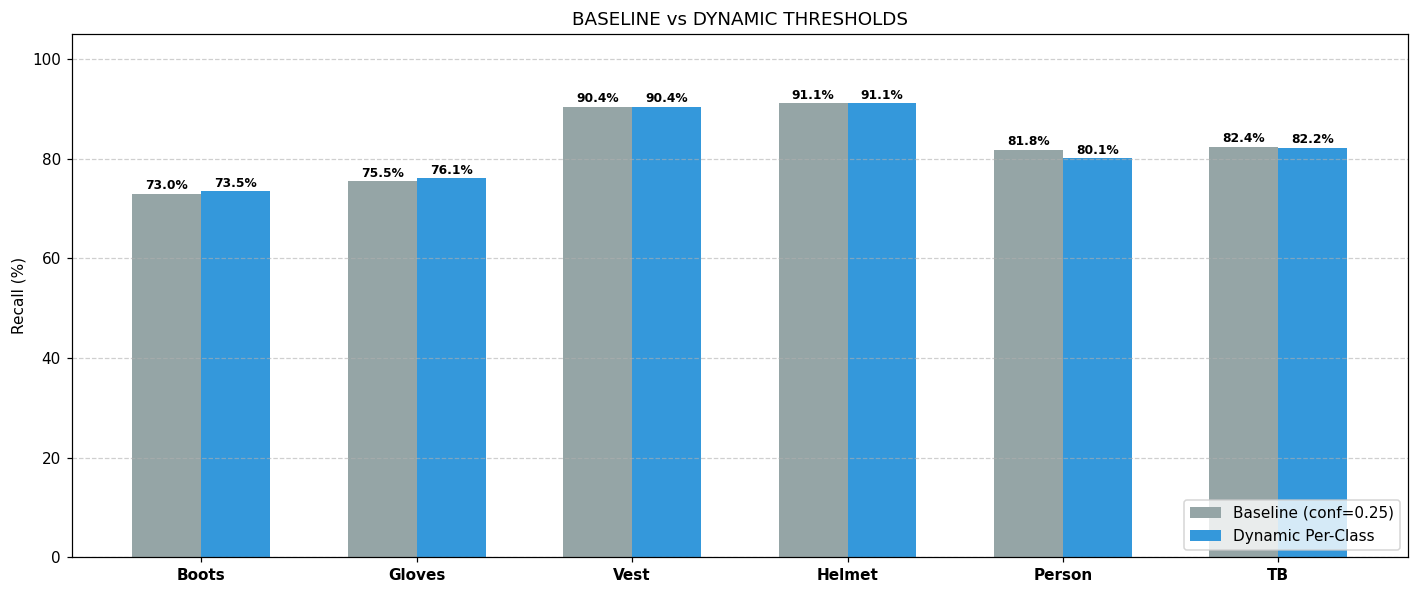


SMALL OBJECTS:
  Boots:  72.99% -> 73.46%
  Gloves: 75.46% -> 76.07%


In [9]:
# Bieu do so sanh Recall
if 'b_rec_vals' in dir() and len(b_rec_vals) == len(CLASS_NAMES):
    plot_order = [4, 3, 2, 1, 0]
    classes_plot = [CLASS_NAMES[index].title() for index in plot_order] + ['TB']
    b_plot = [b_rec_vals[index] for index in plot_order] + [b_avg]
    d_plot = [d_rec_vals[index] for index in plot_order] + [d_avg]

    x = np.arange(len(classes_plot)); width = 0.32
    fig, ax = plt.subplots(figsize=(13, 5.5), dpi=110)
    r1 = ax.bar(x - width / 2, b_plot, width, label='Baseline (conf=0.25)', color='#95a5a6')
    r2 = ax.bar(x + width / 2, d_plot, width, label='Dynamic Per-Class', color='#3498db')
    ax.set_ylabel('Recall (%)'); ax.set_title('BASELINE vs DYNAMIC THRESHOLDS')
    ax.set_xticks(x); ax.set_xticklabels(classes_plot, fontweight='bold')
    ax.legend(loc='lower right'); ax.grid(axis='y', ls='--', alpha=0.6); ax.set_ylim(0, 105)
    for rects in [r1, r2]:
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8, fontweight='bold')
    plt.tight_layout(); plt.show()

    print(f"\nSMALL OBJECTS:")
    print(f"  Boots:  {b_rec_vals[4]:.2f}% -> {d_rec_vals[4]:.2f}%")
    print(f"  Gloves: {b_rec_vals[3]:.2f}% -> {d_rec_vals[3]:.2f}%")

## 8. Truc Quan Hoa Du Doan


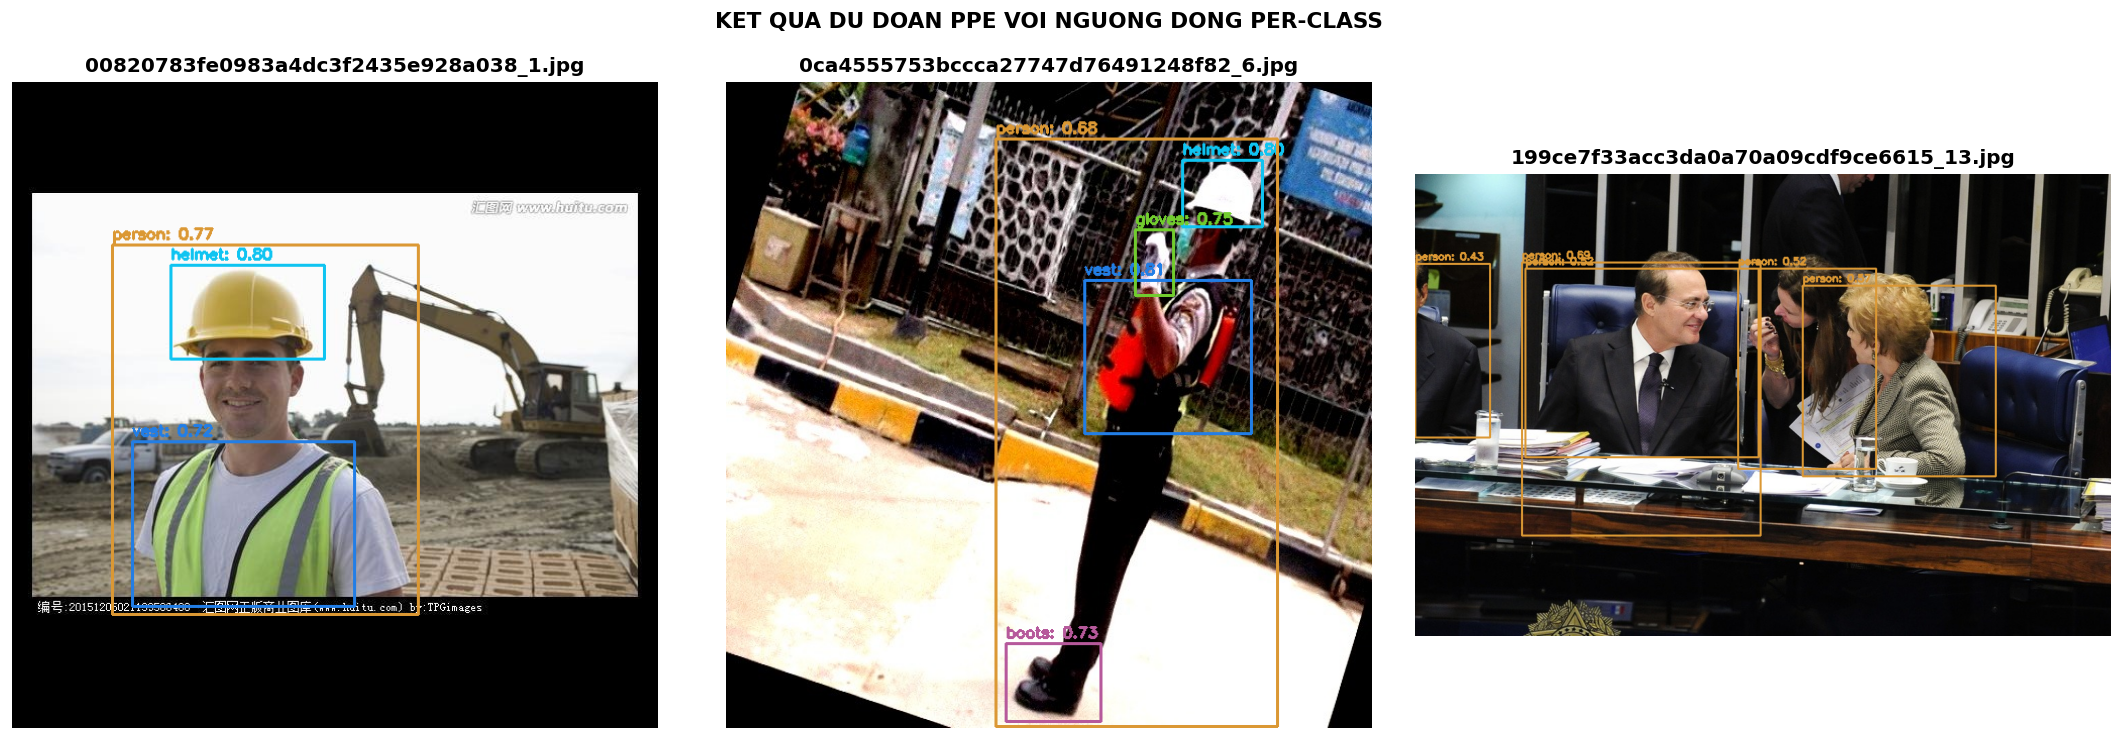

In [10]:
if best_weights_path and best_weights_path.exists():
    eval_img_dir = DATASET_DIR / "images" / EVAL_SPLIT
    eval_imgs = sorted(
        list(eval_img_dir.glob("*.jpg"))
        + list(eval_img_dir.glob("*.jpeg"))
        + list(eval_img_dir.glob("*.png"))
    )
    eval_model = YOLO(str(best_weights_path))

    if eval_imgs:
        sample_indices = sorted(set([0, min(5, len(eval_imgs) - 1), min(12, len(eval_imgs) - 1)]))
        fig, axes = plt.subplots(1, len(sample_indices), figsize=(18, 6), dpi=120)
        if len(sample_indices) == 1:
            axes = [axes]

        for index, sample_index in enumerate(sample_indices):
            image_path = eval_imgs[sample_index]
            image_bgr = cv2.imread(str(image_path))
            min_conf = min(CONFIG["dynamic_thresholds"].values())
            result = eval_model.predict(
                source=str(image_path),
                conf=min_conf,
                imgsz=CONFIG['train_params']['imgsz'],
                device=device,
                verbose=False,
            )[0]
            visible_image = image_bgr.copy()

            if result.boxes is not None:
                for box in result.boxes:
                    class_id = int(box.cls[0])
                    confidence = float(box.conf[0])
                    threshold = CONFIG["dynamic_thresholds"].get(class_id, 0.25)
                    if confidence >= threshold:
                        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
                        color = CLASS_COLORS.get(class_id, (0, 255, 0))
                        cv2.rectangle(visible_image, (x1, y1), (x2, y2), color, 2)
                        cv2.putText(
                            visible_image,
                            f"{CLASS_NAMES[class_id]}: {confidence:.2f}",
                            (x1, max(18, y1 - 6)),
                            cv2.FONT_HERSHEY_SIMPLEX,
                            0.5,
                            color,
                            2,
                        )

            axes[index].imshow(cv2.cvtColor(visible_image, cv2.COLOR_BGR2RGB))
            axes[index].set_title(image_path.name, fontweight='bold')
            axes[index].axis('off')

        plt.suptitle('KET QUA DU DOAN PPE VOI NGUONG DONG PER-CLASS', fontsize=13, fontweight='bold', y=1.02)
        plt.tight_layout(); plt.show()
    else:
        print(f"Khong co anh trong split {EVAL_SPLIT}.")

## 9. Luu Trong So Ve May (Download tu Kaggle)


In [11]:
if IS_KAGGLE and best_weights_path and best_weights_path.exists():
    output_dir = Path('/kaggle/working/output_weights')
    output_dir.mkdir(parents=True, exist_ok=True)

    # Copy best.pt va last.pt
    shutil.copy2(str(best_weights_path), str(output_dir / 'best.pt'))
    last_pt = best_weights_path.parent / 'last.pt'
    if last_pt.exists():
        shutil.copy2(str(last_pt), str(output_dir / 'last.pt'))

    # Copy results.csv va cau hinh train
    res_csv = best_weights_path.parent.parent / 'results.csv'
    if res_csv.exists():
        shutil.copy2(str(res_csv), str(output_dir / 'results.csv'))
    args_yaml = best_weights_path.parent.parent / 'args.yaml'
    if args_yaml.exists():
        shutil.copy2(str(args_yaml), str(output_dir / 'args.yaml'))

    print(f"Da luu trong so tai: {output_dir}")
    print("Ban co the download tu tab Output cua Kaggle.")
    for file_path in sorted(output_dir.iterdir()):
        print(f"  - {file_path.name} ({file_path.stat().st_size / 1024 / 1024:.1f} MB)")
else:
    print("Khong can luu (local) hoac chua co trong so.")

Da luu trong so tai: /kaggle/working/output_weights
Ban co the download tu tab Output cua Kaggle.
  - args.yaml (0.0 MB)
  - best.pt (19.4 MB)
  - last.pt (19.4 MB)
  - results.csv (0.0 MB)
